In [ ]:
import os
import random
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import regularizers
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

sns.set_style("whitegrid")

SEED = 42
np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [ ]:
df = pd.read_csv("breast_cancer_wisconsin_diagnostic.csv")

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nTarget distribution:")
print(df["Diagnosis"].value_counts())

Dataset shape: (569, 31)

Column names:
['radius1', 'texture1', 'perimeter1', 'area1', 'smoothness1', 'compactness1', 'concavity1', 'concave_points1', 'symmetry1', 'fractal_dimension1', 'radius2', 'texture2', 'perimeter2', 'area2', 'smoothness2', 'compactness2', 'concavity2', 'concave_points2', 'symmetry2', 'fractal_dimension2', 'radius3', 'texture3', 'perimeter3', 'area3', 'smoothness3', 'compactness3', 'concavity3', 'concave_points3', 'symmetry3', 'fractal_dimension3', 'Diagnosis']

Data types:
radius1               float64
texture1              float64
perimeter1            float64
area1                 float64
smoothness1           float64
compactness1          float64
concavity1            float64
concave_points1       float64
symmetry1             float64
fractal_dimension1    float64
radius2               float64
texture2              float64
perimeter2            float64
area2                 float64
smoothness2           float64
compactness2          float64
concavity2        

In [ ]:
X = df.drop(columns=["Diagnosis"]).copy()
y = df["Diagnosis"].map({"M": 0, "B": 1}).astype(int)

print("X.shape:", X.shape)
print("\ny.value_counts():")
print(y.value_counts().sort_index())

print("\nX.describe():")
display(X.describe())

X.shape: (569, 30)

y.value_counts():
Diagnosis
0    212
1    357
Name: count, dtype: int64

X.describe():


,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,fractal_dimension1,...,radius3,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


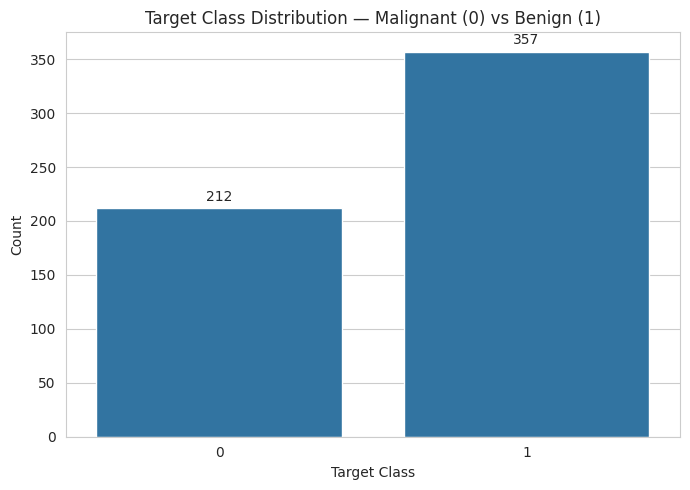

Class percentages:
Diagnosis
0    37.26
1    62.74
Name: proportion, dtype: float64

Interpretation: the dataset has a mild class imbalance (212 malignant vs 357 benign). Because both classes have substantial representation and the split is stratified, no resampling is required for this assignment.


In [ ]:
plt.figure(figsize=(7, 5))
ax = sns.countplot(x=y)
ax.set_title("Target Class Distribution — Malignant (0) vs Benign (1)")
ax.set_xlabel("Target Class")
ax.set_ylabel("Count")

for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3)

plt.tight_layout()
plt.show()

print("Class percentages:")
print((y.value_counts(normalize=True).sort_index() * 100).round(2))

print(
    "\nInterpretation: the dataset has a mild class imbalance "
    "(212 malignant vs 357 benign). Because both classes have substantial "
    "representation and the split is stratified, no resampling is required "
    "for this assignment."
)

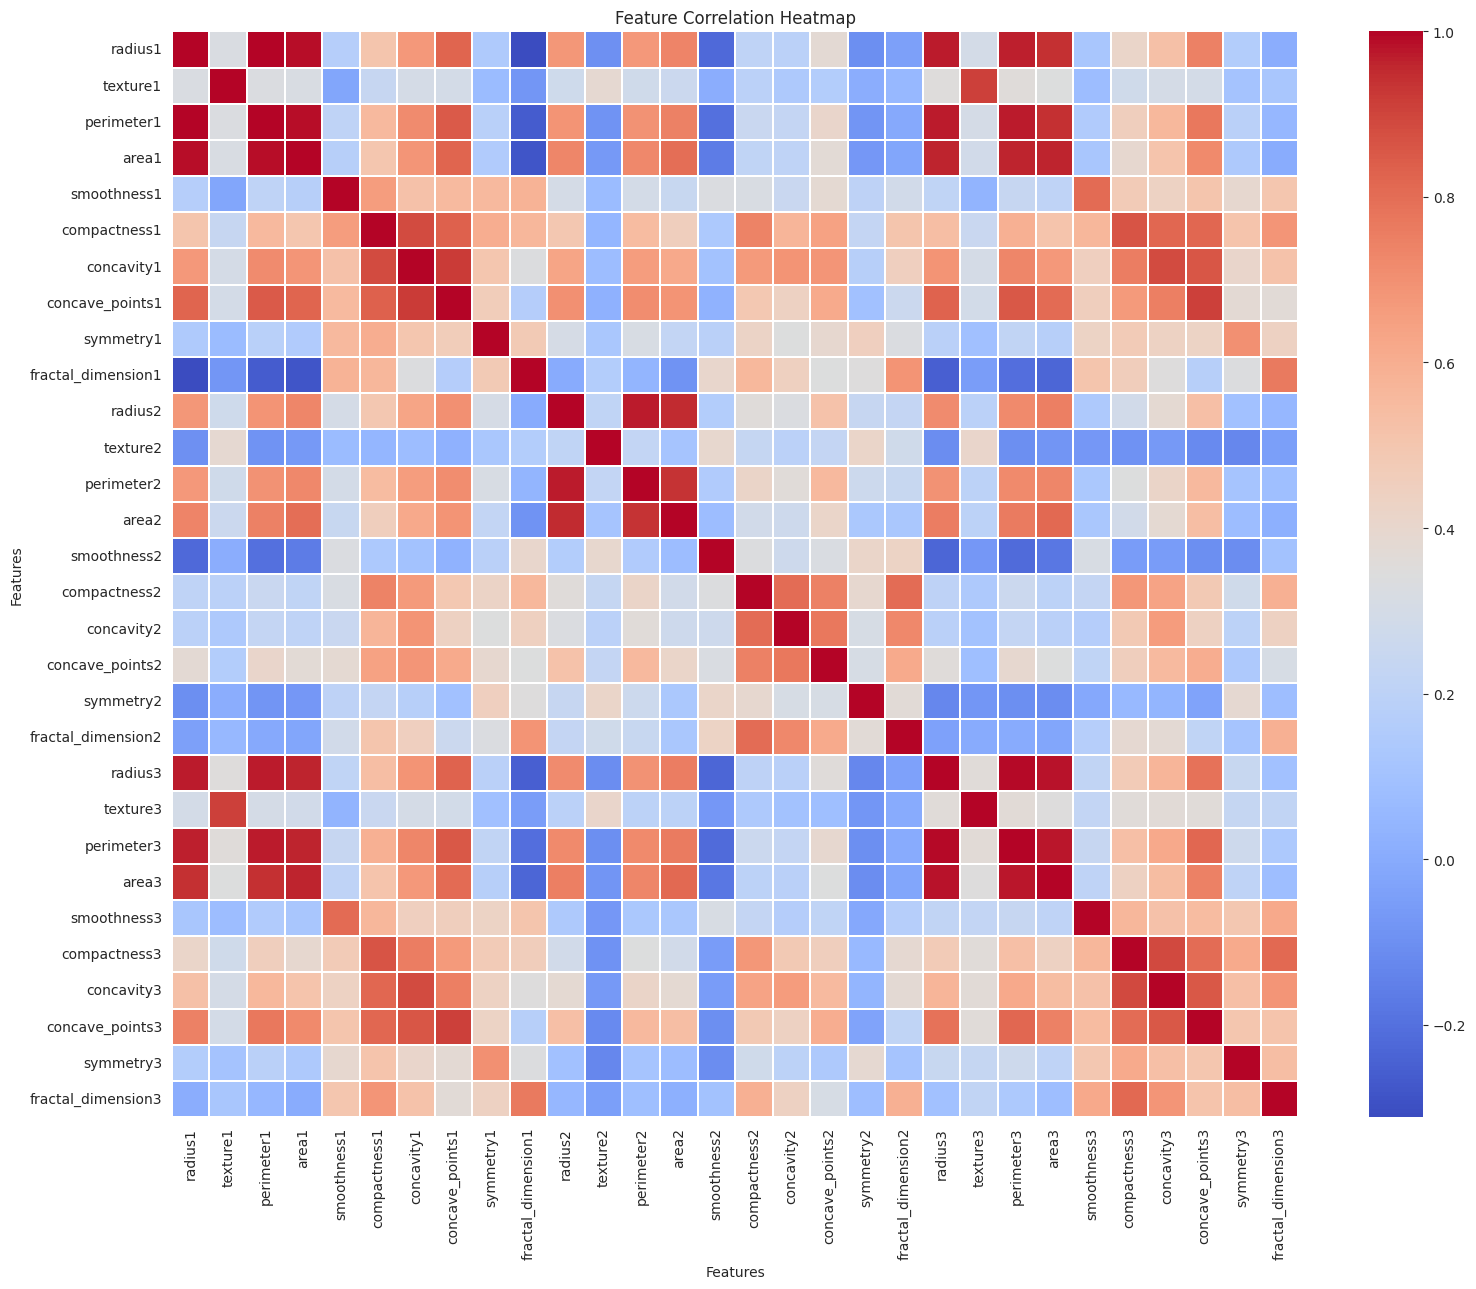

Top correlated feature pairs:
radius1 ↔ perimeter1: correlation = 0.9979
radius3 ↔ perimeter3: correlation = 0.9937
radius1 ↔ area1: correlation = 0.9874
perimeter1 ↔ area1: correlation = 0.9865
radius3 ↔ area3: correlation = 0.9840


In [ ]:
corr = X.corr()

plt.figure(figsize=(16, 13))
sns.heatmap(
    corr,
    annot=False,
    cmap="coolwarm",
    linewidths=0.3
)
plt.title("Feature Correlation Heatmap")
plt.xlabel("Features")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

corr_pairs = []
cols = corr.columns

for i in range(len(cols)):
    for j in range(i + 1, len(cols)):
        corr_pairs.append(
            (abs(corr.iloc[i, j]), corr.iloc[i, j], cols[i], cols[j])
        )

top_pairs = sorted(corr_pairs, reverse=True)[:5]

print("Top correlated feature pairs:")
for abs_value, signed_value, col1, col2 in top_pairs:
    print(f"{col1} ↔ {col2}: correlation = {signed_value:.4f}")

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape :", y_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting class distribution:")
print(y_test.value_counts().sort_index())

X_train shape: (455, 30)
X_test shape : (114, 30)
y_train shape: (455,)
y_test shape : (114,)

Training class distribution:
Diagnosis
0    170
1    285
Name: count, dtype: int64

Testing class distribution:
Diagnosis
0    42
1    72
Name: count, dtype: int64


In [ ]:
scaler = StandardScaler()

scaler.fit(X_train)

X_train_sc = scaler.transform(X_train)
X_test_sc = scaler.transform(X_test)

print("X_train_sc shape:", X_train_sc.shape)
print("X_test_sc shape :", X_test_sc.shape)

print("\nTraining means (rounded):")
print(np.round(X_train_sc.mean(axis=0), 2))

print("\nTraining standard deviations (rounded):")
print(np.round(X_train_sc.std(axis=0), 2))

X_train_sc shape: (455, 30)
X_test_sc shape : (114, 30)

Training means (rounded):
[-0.  0. -0. -0.  0. -0. -0.  0. -0.  0. -0. -0.  0.  0. -0. -0.  0. -0.
  0.  0.  0. -0. -0.  0.  0. -0.  0. -0. -0.  0.]

Training standard deviations (rounded):
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1.]


### Task 1.6 — WHY scaling is required for neural networks

Gradient-based optimizers such as SGD and Adam work more stably when input features are on comparable scales. In this dataset, variables such as `area1` can have values in the hundreds or thousands, while variables such as `fractal_dimension1` are much smaller. Without scaling, large-range variables can dominate early gradient updates and slow or bias learning. `StandardScaler` transforms each feature using the training-set mean and standard deviation.

The scaler is fitted only on `X_train` because fitting on `X_test` would leak information from the test set into the training pipeline.

In [ ]:
model_slp = keras.Sequential([
    keras.layers.Input(shape=(30,)),
    keras.layers.Dense(1, activation="sigmoid")
], name="SLP")

model_slp.summary()

Model: "SLP"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 1)              │            31 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31 (124.00 B)

 Trainable params: 31 (124.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model_slp.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Expected trainable parameters: 31 (30 weights + 1 bias)")

Expected trainable parameters: 31 (30 weights + 1 bias)


### Task 2.2 — WHY binary cross-entropy?

Binary cross-entropy is appropriate because the target is a binary class and the sigmoid output represents the probability of class 1. The loss measures how closely the predicted probability matches the true binary label.

In [ ]:
history_slp = model_slp.fit(
    X_train_sc,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

Epoch 1/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.4939 - loss: 0.8112 - val_accuracy: 0.3261 - val_loss: 0.8657
Epoch 2/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5868 - loss: 0.7331 - val_accuracy: 0.4783 - val_loss: 0.7958
Epoch 3/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6724 - loss: 0.6666 - val_accuracy: 0.5217 - val_loss: 0.7356
Epoch 4/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7286 - loss: 0.6107 - val_accuracy: 0.5870 - val_loss: 0.6840
Epoch 5/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7555 - loss: 0.5636 - val_accuracy: 0.6304 - val_loss: 0.6395
Epoch 6/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7800 - loss: 0.5237 - val_accuracy: 0.6522 - val_loss: 0.6008
Epoch 7/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8142 - loss: 0.4894 - val_accuracy: 0.6957 - val_loss: 0.5668
Epoch 8/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8386 - loss: 0.4597 - val_accuracy: 0.7826 - val_loss

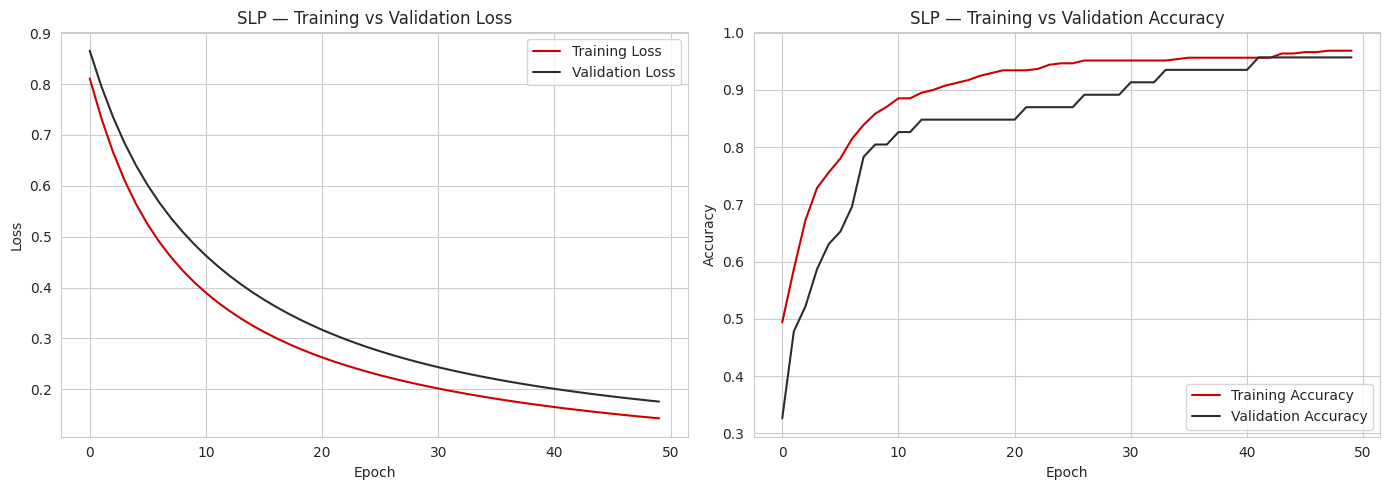

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    history_slp.history["loss"],
    label="Training Loss",
    color="#CC0000"
)
axes[0].plot(
    history_slp.history["val_loss"],
    label="Validation Loss",
    color="#2C2C2C"
)
axes[0].set_title("SLP — Training vs Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(
    history_slp.history["accuracy"],
    label="Training Accuracy",
    color="#CC0000"
)
axes[1].plot(
    history_slp.history["val_accuracy"],
    label="Validation Accuracy",
    color="#2C2C2C"
)
axes[1].set_title("SLP — Training vs Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

SLP Test Accuracy: 0.9474

Classification Report:
              precision    recall  f1-score   support

   Malignant       0.95      0.90      0.93        42
      Benign       0.95      0.97      0.96        72

    accuracy                           0.95       114
   macro avg       0.95      0.94      0.94       114
weighted avg       0.95      0.95      0.95       114



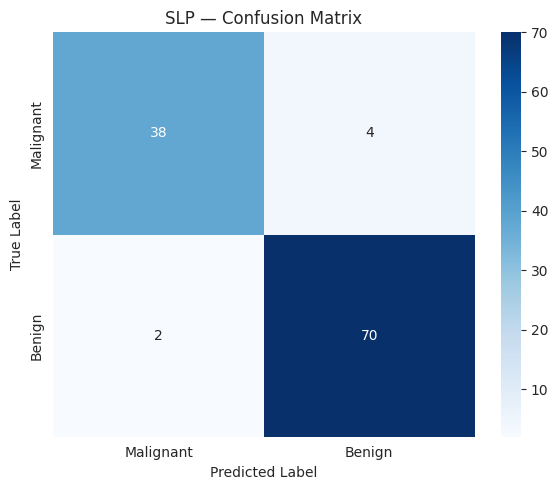

In [ ]:
slp_loss, slp_acc = model_slp.evaluate(X_test_sc, y_test, verbose=0)

y_pred_slp_prob = model_slp.predict(X_test_sc, verbose=0).ravel()
y_pred_slp = (y_pred_slp_prob > 0.5).astype(int)

print(f"SLP Test Accuracy: {slp_acc:.4f}")
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_slp,
    target_names=["Malignant", "Benign"],
    zero_division=0
))

cm_slp = confusion_matrix(y_test, y_pred_slp)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_slp,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Malignant", "Benign"],
    yticklabels=["Malignant", "Benign"]
)
plt.title("SLP — Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

### Task 2.6 — SLP limitation

An SLP with one sigmoid neuron can learn only a linear decision boundary (one hyperplane in the 30-dimensional feature space). Breast-cancer diagnosis is unlikely to be perfectly linearly separable, so the SLP is used as a baseline. Hidden layers in the MLP allow the network to learn non-linear feature interactions.

In [ ]:
model_mlp = keras.Sequential([
    keras.layers.Input(shape=(30,)),
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dense(1, activation="sigmoid")
], name="MLP_ReLU")

model_mlp.summary()

manual_params = (30 * 64 + 64) + (64 * 32 + 32) + (32 * 1 + 1)
print("Manual parameter count:", manual_params)

Model: "MLP_ReLU"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 64)             │         1,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,097 (16.00 KB)

 Trainable params: 4,097 (16.00 KB)

 Non-trainable params: 0 (0.00 B)

Manual parameter count: 4097


### Task 3.2 — WHY hidden layers?

Each Dense layer learns a transformation of its inputs. Hidden layers allow the network to compose non-linear transformations and learn interactions that a single linear layer cannot represent. The Universal Approximation Theorem shows that a sufficiently wide hidden layer can approximate broad classes of functions; in practice, multiple hidden layers can provide useful hierarchical representations.

In [ ]:
model_mlp.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

history_mlp = model_mlp.fit(
    X_train_sc,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

Epoch 1/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.6968 - loss: 0.5583 - val_accuracy: 0.7826 - val_loss: 0.4866
Epoch 2/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9169 - loss: 0.3125 - val_accuracy: 0.8696 - val_loss: 0.3181
Epoch 3/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9413 - loss: 0.1989 - val_accuracy: 0.9348 - val_loss: 0.2303
Epoch 4/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9535 - loss: 0.1426 - val_accuracy: 0.9565 - val_loss: 0.1781
Epoch 5/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9780 - loss: 0.1118 - val_accuracy: 0.9565 - val_loss: 0.1459
Epoch 6/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9804 - loss: 0.0931 - val_accuracy: 0.9565 - val_loss: 0.1244
Epoch 7/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9804 - loss: 0.0807 - val_accuracy: 0.9565 - val_loss: 0.1094
Epoch 8/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9829 - loss: 0.0720 - val_accuracy: 0.9565 - 

In [ ]:
def build_activation_mlp(activation, name):
    model = keras.Sequential([
        keras.layers.Input(shape=(30,)),
        keras.layers.Dense(64, activation=activation),
        keras.layers.Dense(32, activation=activation),
        keras.layers.Dense(1, activation="sigmoid")
    ], name=name)

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model

model_tanh = build_activation_mlp("tanh", "MLP_Tanh")
model_sigmoid = build_activation_mlp("sigmoid", "MLP_Sigmoid")

history_tanh = model_tanh.fit(
    X_train_sc, y_train,
    epochs=100, batch_size=32,
    validation_split=0.1, verbose=1
)

history_sigmoid = model_sigmoid.fit(
    X_train_sc, y_train,
    epochs=100, batch_size=32,
    validation_split=0.1, verbose=1
)

Epoch 1/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.7824 - loss: 0.4799 - val_accuracy: 0.8478 - val_loss: 0.3138
Epoch 2/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9169 - loss: 0.2026 - val_accuracy: 0.9348 - val_loss: 0.2138
Epoch 3/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9560 - loss: 0.1358 - val_accuracy: 0.9565 - val_loss: 0.1546
Epoch 4/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9658 - loss: 0.1062 - val_accuracy: 0.9565 - val_loss: 0.1196
Epoch 5/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9780 - loss: 0.0908 - val_accuracy: 0.9783 - val_loss: 0.1004
Epoch 6/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9804 - loss: 0.0814 - val_accuracy: 0.9783 - val_loss: 0.0889
Epoch 7/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9853 - loss: 0.0746 - val_accuracy: 0.9783 - val_loss: 0.0812
Epoch 8/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9853 - loss: 0.0695 - val_accuracy: 0.9783 - 

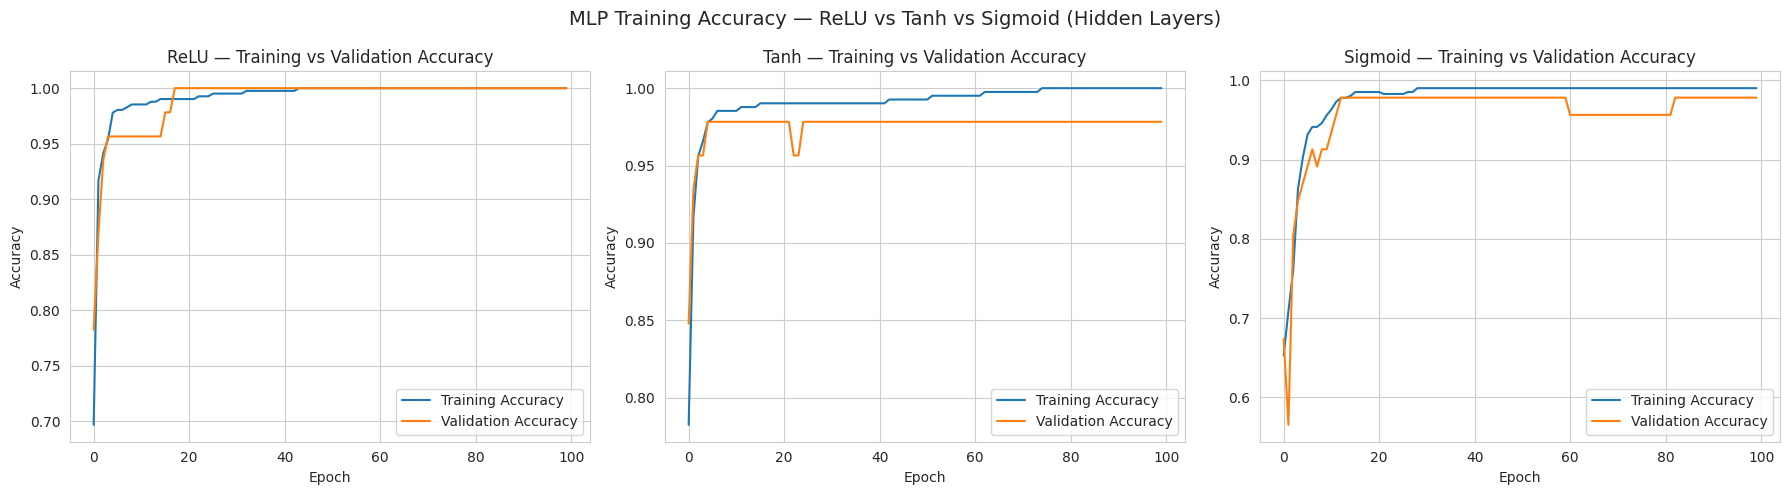

In [ ]:
histories_activation = {
    "ReLU": history_mlp,
    "Tanh": history_tanh,
    "Sigmoid": history_sigmoid
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, history) in zip(axes, histories_activation.items()):
    ax.plot(history.history["accuracy"], label="Training Accuracy")
    ax.plot(history.history["val_accuracy"], label="Validation Accuracy")
    ax.set_title(f"{name} — Training vs Validation Accuracy")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Accuracy")
    ax.legend()

fig.suptitle(
    "MLP Training Accuracy — ReLU vs Tanh vs Sigmoid (Hidden Layers)",
    fontsize=14
)
plt.tight_layout()
plt.show()

In [ ]:
best_activation_name = max(
    histories_activation,
    key=lambda name: max(histories_activation[name].history["val_accuracy"])
)

best_activation_history = histories_activation[best_activation_name]

models_activation = {
    "ReLU": model_mlp,
    "Tanh": model_tanh,
    "Sigmoid": model_sigmoid
}

best_activation_model = models_activation[best_activation_name]

print("Best activation by maximum validation accuracy:", best_activation_name)
print(
    "Best validation accuracy:",
    max(best_activation_history.history["val_accuracy"])
)

Best activation by maximum validation accuracy: ReLU
Best validation accuracy: 1.0


### Task 3.5 — Activation functions

- **ReLU:** `max(0, x)`. It is computationally simple and generally converges quickly; negative inputs have zero gradient, which creates a possible dying-ReLU issue.
- **Tanh:** outputs values in `(-1, 1)` and is zero-centred, but can suffer from vanishing gradients.
- **Sigmoid in hidden layers:** outputs values in `(0, 1)`, is not zero-centred, and can suffer strongly from vanishing gradients. Sigmoid remains appropriate for the final binary-classification output layer.

The notebook selects the best variant using maximum validation accuracy rather than assuming a winner before training.

Best MLP (ReLU) Test Accuracy: 0.9561

Classification Report:
              precision    recall  f1-score   support

   Malignant       0.91      0.98      0.94        42
      Benign       0.99      0.94      0.96        72

    accuracy                           0.96       114
   macro avg       0.95      0.96      0.95       114
weighted avg       0.96      0.96      0.96       114



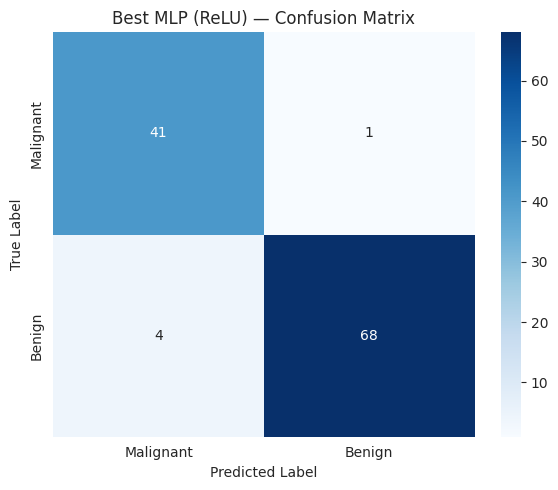

SLP Test Accuracy: 0.9474
Best MLP Test Accuracy: 0.9561


In [ ]:
best_prob = best_activation_model.predict(X_test_sc, verbose=0).ravel()
best_pred = (best_prob > 0.5).astype(int)

best_test_accuracy = accuracy_score(y_test, best_pred)

print(f"Best MLP ({best_activation_name}) Test Accuracy: {best_test_accuracy:.4f}")
print("\nClassification Report:")
print(classification_report(
    y_test,
    best_pred,
    target_names=["Malignant", "Benign"],
    zero_division=0
))

cm_best = confusion_matrix(y_test, best_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_best,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Malignant", "Benign"],
    yticklabels=["Malignant", "Benign"]
)
plt.title(f"Best MLP ({best_activation_name}) — Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

print(f"SLP Test Accuracy: {slp_acc:.4f}")
print(f"Best MLP Test Accuracy: {best_test_accuracy:.4f}")

In [ ]:
def build_base_128_64_model(name="MLP_128_64"):
    model = keras.Sequential([
        keras.layers.Input(shape=(30,)),
        keras.layers.Dense(128, activation="relu"),
        keras.layers.Dense(64, activation="relu"),
        keras.layers.Dense(1, activation="sigmoid")
    ], name=name)

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model

model_es = build_base_128_64_model("MLP_EarlyStopping")

In [ ]:
es = EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True,
    verbose=1
)

history_es = model_es.fit(
    X_train_sc,
    y_train,
    epochs=300,
    batch_size=32,
    validation_split=0.1,
    callbacks=[es],
    verbose=1
)

stopping_epoch = len(history_es.history["loss"])
print("Training stopped after epochs:", stopping_epoch)

Epoch 1/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.8655 - loss: 0.4214 - val_accuracy: 0.9348 - val_loss: 0.2532
Epoch 2/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9609 - loss: 0.1538 - val_accuracy: 0.9348 - val_loss: 0.1690
Epoch 3/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9731 - loss: 0.0944 - val_accuracy: 0.9348 - val_loss: 0.1269
Epoch 4/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9853 - loss: 0.0715 - val_accuracy: 0.9783 - val_loss: 0.0945
Epoch 5/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9829 - loss: 0.0606 - val_accuracy: 0.9783 - val_loss: 0.0754
Epoch 6/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9878 - loss: 0.0540 - val_accuracy: 0.9783 - val_loss: 0.0651
Epoch 7/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9878 - loss: 0.0486 - val_accuracy: 0.9783 - val_loss: 0.0589
Epoch 8/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9878 - loss: 0.0440 - val_accuracy: 0.9783 - 

### Task 4.3 — WHY Early Stopping?

- `monitor='val_loss'`: validation loss measures generalisation; training loss alone can continue improving while validation performance worsens.
- `patience=15`: allows temporary plateaus before stopping.
- `restore_best_weights=True`: restores the weights from the epoch with the best monitored validation loss rather than keeping later, potentially overfit weights.
- `verbose=1`: reports the stopping process in the training output.

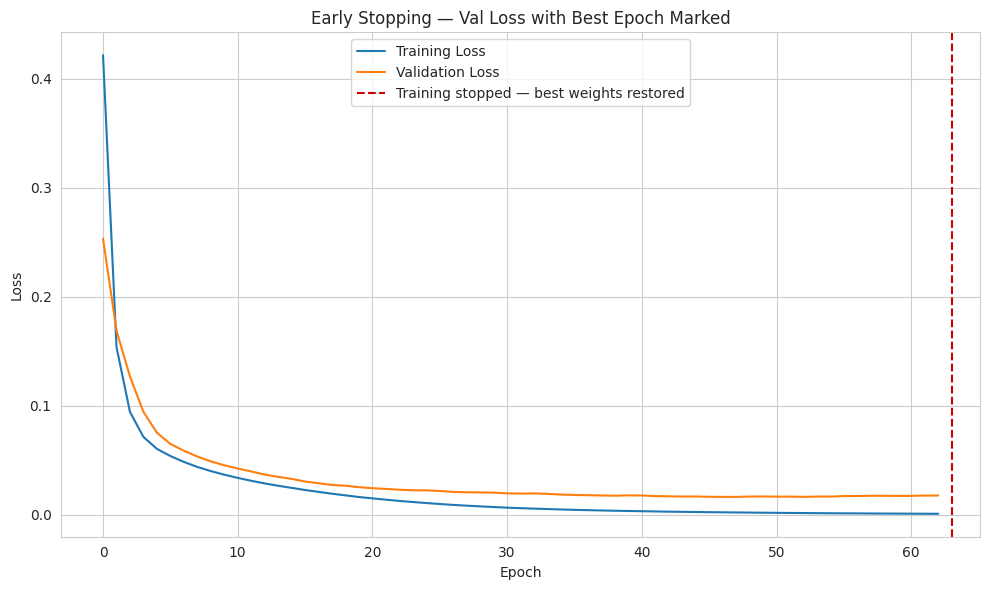

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(history_es.history["loss"], label="Training Loss")
plt.plot(history_es.history["val_loss"], label="Validation Loss")

plt.axvline(
    stopping_epoch,
    color="#CC0000",
    linestyle="--",
    label="Training stopped — best weights restored"
)

plt.title("Early Stopping — Val Loss with Best Epoch Marked")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.show()

Epoch 1/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.8826 - loss: 0.4117 - val_accuracy: 0.8913 - val_loss: 0.2744
Epoch 2/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9535 - loss: 0.1719 - val_accuracy: 0.9565 - val_loss: 0.1824
Epoch 3/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9658 - loss: 0.1087 - val_accuracy: 0.9565 - val_loss: 0.1307
Epoch 4/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9829 - loss: 0.0798 - val_accuracy: 0.9783 - val_loss: 0.0963
Epoch 5/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9829 - loss: 0.0659 - val_accuracy: 0.9783 - val_loss: 0.0780
Epoch 6/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9829 - loss: 0.0576 - val_accuracy: 0.9783 - val_loss: 0.0678
Epoch 7/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9853 - loss: 0.0510 - val_accuracy: 0.9783 - val_loss: 0.0607
Epoch 8/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9878 - loss: 0.0456 - val_accuracy: 0.9783 - 

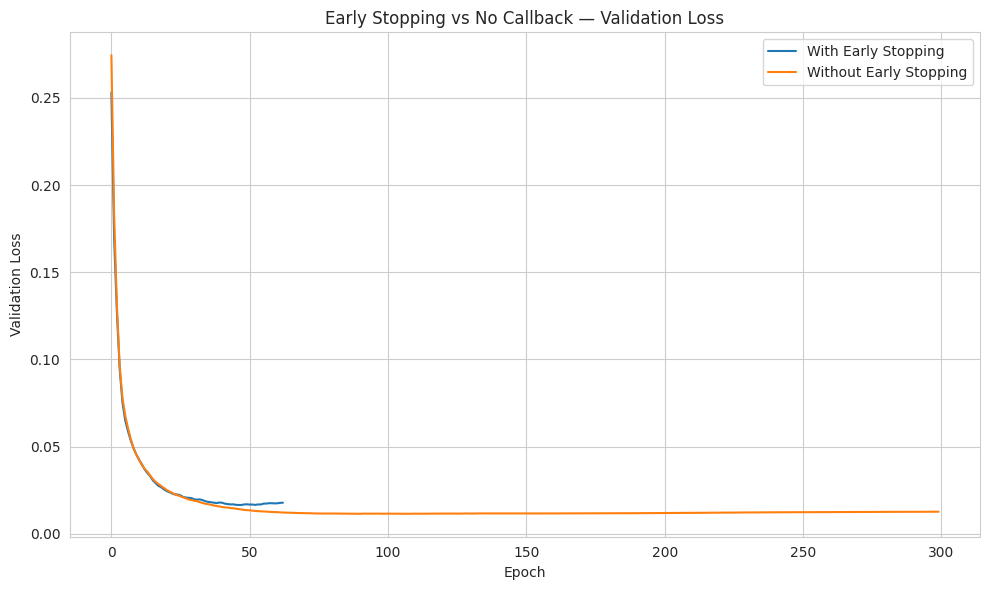

First detected epoch where no-callback val_loss rises: 77
Early Stopping best val_loss: 0.016555
No Early Stopping best val_loss: 0.011507
Early Stopping test accuracy: 0.9649
No Early Stopping test accuracy: 0.9561


In [ ]:
model_no_es = build_base_128_64_model("MLP_NoEarlyStopping")

history_no_es = model_no_es.fit(
    X_train_sc,
    y_train,
    epochs=300,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

plt.figure(figsize=(10, 6))
plt.plot(
    history_es.history["val_loss"],
    label="With Early Stopping"
)
plt.plot(
    history_no_es.history["val_loss"],
    label="Without Early Stopping"
)
plt.title("Early Stopping vs No Callback — Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.legend()
plt.tight_layout()
plt.show()

val_loss_no_es = np.array(history_no_es.history["val_loss"])
increase_indices = np.where(val_loss_no_es[1:] > val_loss_no_es[:-1])[0]

if len(increase_indices) > 0:
    first_rise_epoch = int(increase_indices[0] + 2)
    print("First detected epoch where no-callback val_loss rises:", first_rise_epoch)
else:
    first_rise_epoch = None
    print("No validation-loss rise detected in the 300-epoch run.")

es_pred = (model_es.predict(X_test_sc, verbose=0).ravel() > 0.5).astype(int)
no_es_pred = (model_no_es.predict(X_test_sc, verbose=0).ravel() > 0.5).astype(int)

es_acc = accuracy_score(y_test, es_pred)
no_es_acc = accuracy_score(y_test, no_es_pred)

best_es_val_loss = min(history_es.history["val_loss"])
best_no_es_val_loss = min(history_no_es.history["val_loss"])

print(f"Early Stopping best val_loss: {best_es_val_loss:.6f}")
print(f"No Early Stopping best val_loss: {best_no_es_val_loss:.6f}")
print(f"Early Stopping test accuracy: {es_acc:.4f}")
print(f"No Early Stopping test accuracy: {no_es_acc:.4f}")

In [ ]:
def build_dropout_model(rate=0.3, name="MLP_Dropout"):
    model = keras.Sequential([
        keras.layers.Input(shape=(30,)),
        keras.layers.Dense(128, activation="relu"),
        keras.layers.Dropout(rate),
        keras.layers.Dense(64, activation="relu"),
        keras.layers.Dropout(rate),
        keras.layers.Dense(1, activation="sigmoid")
    ], name=name)

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model

model_drop = build_dropout_model(0.3, "MLP_Dropout_0.3")
model_drop.summary()

Model: "MLP_Dropout_0.3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_16 (Dense)                │ (None, 128)            │         3,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,289 (48.00 KB)

 Trainable params: 12,289 (48.00 KB)

 Non-trainable params: 0 (0.00 B)

### Task 5.2 — WHY Dropout?

`Dropout(rate=0.3)` randomly sets 30% of the relevant activations to zero during training. This prevents the network from relying too heavily on individual neurons and encourages distributed representations. During inference, Dropout is disabled so the full network contributes to predictions.

In [ ]:
es_drop = EarlyStopping(
    monitor="val_loss",
    patience=20,
    restore_best_weights=True,
    verbose=1
)

history_drop = model_drop.fit(
    X_train_sc,
    y_train,
    epochs=300,
    batch_size=32,
    validation_split=0.1,
    callbacks=[es_drop],
    verbose=1
)

Epoch 1/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step - accuracy: 0.7800 - loss: 0.4960 - val_accuracy: 0.9130 - val_loss: 0.3126
Epoch 2/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9267 - loss: 0.2271 - val_accuracy: 0.9130 - val_loss: 0.2204
Epoch 3/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9535 - loss: 0.1471 - val_accuracy: 0.9130 - val_loss: 0.1843
Epoch 4/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9658 - loss: 0.1145 - val_accuracy: 0.9565 - val_loss: 0.1498
Epoch 5/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9707 - loss: 0.1006 - val_accuracy: 0.9565 - val_loss: 0.1173
Epoch 6/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9756 - loss: 0.0869 - val_accuracy: 0.9565 - val_loss: 0.1034
Epoch 7/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9756 - loss: 0.0763 - val_accuracy: 0.9565 - val_loss: 0.0949
Epoch 8/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9804 - loss: 0.0610 - val_accuracy: 0.

Epoch 1/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.7188 - loss: 0.5402 - val_accuracy: 0.8913 - val_loss: 0.3208
Epoch 2/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9487 - loss: 0.2180 - val_accuracy: 0.8913 - val_loss: 0.2074
Epoch 3/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9511 - loss: 0.1322 - val_accuracy: 0.9348 - val_loss: 0.1564
Epoch 4/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9707 - loss: 0.0949 - val_accuracy: 0.9565 - val_loss: 0.1168
Epoch 5/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9804 - loss: 0.0768 - val_accuracy: 0.9783 - val_loss: 0.0939
Epoch 6/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9878 - loss: 0.0651 - val_accuracy: 0.9783 - val_loss: 0.0826
Epoch 7/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9829 - loss: 0.0617 - val_accuracy: 0.9783 - val_loss: 0.0762
Epoch 8/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9853 - loss: 0.0540 - val_accuracy: 0.9783 - 

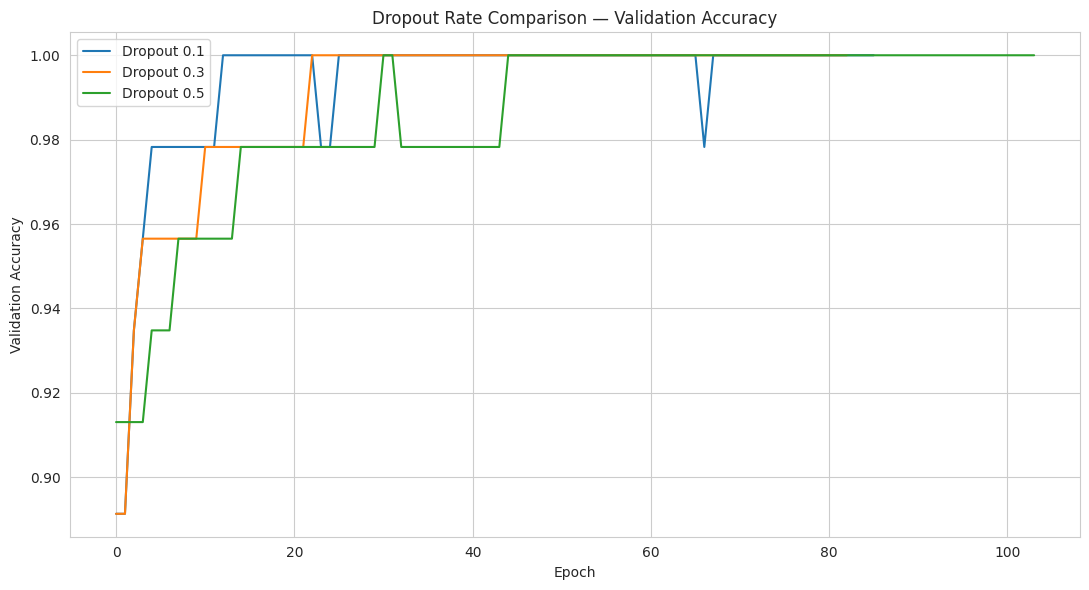

Best dropout rate by maximum validation accuracy: 0.1


In [ ]:
dropout_rates = [0.1, 0.3, 0.5]
dropout_models = {}
dropout_histories = {}

for rate in dropout_rates:
    name = f"MLP_Dropout_{rate}"
    model = build_dropout_model(rate, name)

    callback = EarlyStopping(
        monitor="val_loss",
        patience=20,
        restore_best_weights=True,
        verbose=1
    )

    history = model.fit(
        X_train_sc,
        y_train,
        epochs=200,
        batch_size=32,
        validation_split=0.1,
        callbacks=[callback],
        verbose=1
    )

    dropout_models[rate] = model
    dropout_histories[rate] = history

plt.figure(figsize=(11, 6))

for rate in dropout_rates:
    plt.plot(
        dropout_histories[rate].history["val_accuracy"],
        label=f"Dropout {rate}"
    )

plt.title("Dropout Rate Comparison — Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.tight_layout()
plt.show()

best_dropout_rate = max(
    dropout_rates,
    key=lambda r: max(dropout_histories[r].history["val_accuracy"])
)

print("Best dropout rate by maximum validation accuracy:", best_dropout_rate)

### Task 5.4 — Dropout rate trade-off

A low rate such as 0.1 may provide insufficient regularisation. A high rate such as 0.5 removes many activations during each batch and can cause underfitting or slower learning. The selected rate is therefore based on validation performance rather than assumed in advance.

Best Dropout (0.1) Test Accuracy: 0.9474

Classification Report:
              precision    recall  f1-score   support

   Malignant       0.89      0.98      0.93        42
      Benign       0.99      0.93      0.96        72

    accuracy                           0.95       114
   macro avg       0.94      0.95      0.94       114
weighted avg       0.95      0.95      0.95       114



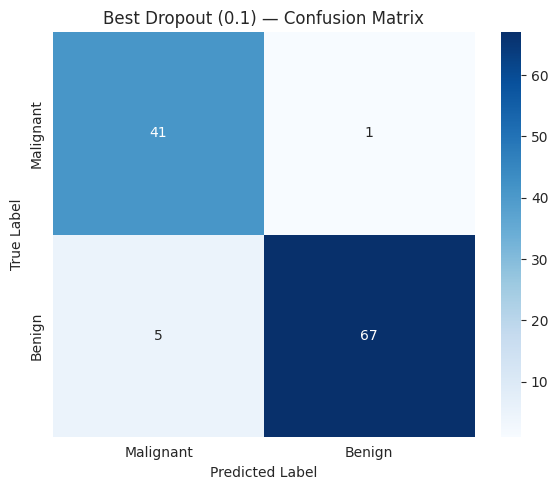

In [ ]:
best_dropout_model = dropout_models[best_dropout_rate]
best_dropout_pred = (
    best_dropout_model.predict(X_test_sc, verbose=0).ravel() > 0.5
).astype(int)

best_dropout_acc = accuracy_score(y_test, best_dropout_pred)

print(f"Best Dropout ({best_dropout_rate}) Test Accuracy: {best_dropout_acc:.4f}")
print("\nClassification Report:")
print(classification_report(
    y_test,
    best_dropout_pred,
    target_names=["Malignant", "Benign"],
    zero_division=0
))

cm_dropout = confusion_matrix(y_test, best_dropout_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_dropout,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Malignant", "Benign"],
    yticklabels=["Malignant", "Benign"]
)
plt.title(f"Best Dropout ({best_dropout_rate}) — Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

In [ ]:
def build_regularized_model(reg_type, name):
    if reg_type == "l2":
        reg = regularizers.l2(0.001)
        reg2 = regularizers.l2(0.001)
    elif reg_type == "l1":
        reg = regularizers.l1(0.001)
        reg2 = regularizers.l1(0.001)
    elif reg_type == "l1_l2":
        reg = regularizers.l1_l2(l1=0.0001, l2=0.001)
        reg2 = regularizers.l1_l2(l1=0.0001, l2=0.001)
    else:
        raise ValueError("reg_type must be 'l1', 'l2', or 'l1_l2'.")

    model = keras.Sequential([
        keras.layers.Input(shape=(30,)),
        keras.layers.Dense(128, activation="relu", kernel_regularizer=reg),
        keras.layers.Dense(64, activation="relu", kernel_regularizer=reg2),
        keras.layers.Dense(1, activation="sigmoid")
    ], name=name)

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model

In [ ]:
regularization_configs = {
    "L2": "l2",
    "L1": "l1",
    "L1-L2": "l1_l2"
}

regularized_models = {}
regularized_histories = {}

for label, reg_type in regularization_configs.items():
    model = build_regularized_model(reg_type, f"MLP_{label}")

    callback = EarlyStopping(
        monitor="val_loss",
        patience=20,
        restore_best_weights=True,
        verbose=1
    )

    history = model.fit(
        X_train_sc,
        y_train,
        epochs=300,
        batch_size=32,
        validation_split=0.1,
        callbacks=[callback],
        verbose=1
    )

    regularized_models[label] = model
    regularized_histories[label] = history

print("Regularization models trained:", list(regularized_models.keys()))

Epoch 1/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.8582 - loss: 0.5614 - val_accuracy: 0.9130 - val_loss: 0.4199
Epoch 2/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9609 - loss: 0.3055 - val_accuracy: 0.9348 - val_loss: 0.3201
Epoch 3/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9707 - loss: 0.2387 - val_accuracy: 0.9348 - val_loss: 0.2702
Epoch 4/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9780 - loss: 0.2104 - val_accuracy: 0.9783 - val_loss: 0.2367
Epoch 5/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9780 - loss: 0.1953 - val_accuracy: 0.9783 - val_loss: 0.2173
Epoch 6/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9853 - loss: 0.1843 - val_accuracy: 0.9783 - val_loss: 0.2052
Epoch 7/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9853 - loss: 0.1748 - val_accuracy: 0.9783 - val_loss: 0.1951
Epoch 8/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9853 - loss: 0.1665 - val_accuracy: 0.9783 - 

### Task 6.2 — WHY L2 regularization?

L2 adds a penalty proportional to `λ × Σw²` to the loss. It discourages large weights and tends to produce smoother decision boundaries. With `λ=0.001`, the penalty is moderate; a very large value could over-regularize the model and cause underfitting.

### Task 6.3 — L1 regularization

L1 adds `λ × Σ|w|` to the loss. Unlike L2, L1 encourages sparsity, so some weights can become exactly or effectively zero. This can act like feature selection, which is useful when some of the 30 features contribute little predictive information.

### Task 6.4 — L1-L2 / ElasticNet

L1-L2 combines both penalties. L2 helps manage correlated feature groups, while L1 encourages sparsity in less useful weights. This combination can therefore balance weight shrinkage and feature selection.

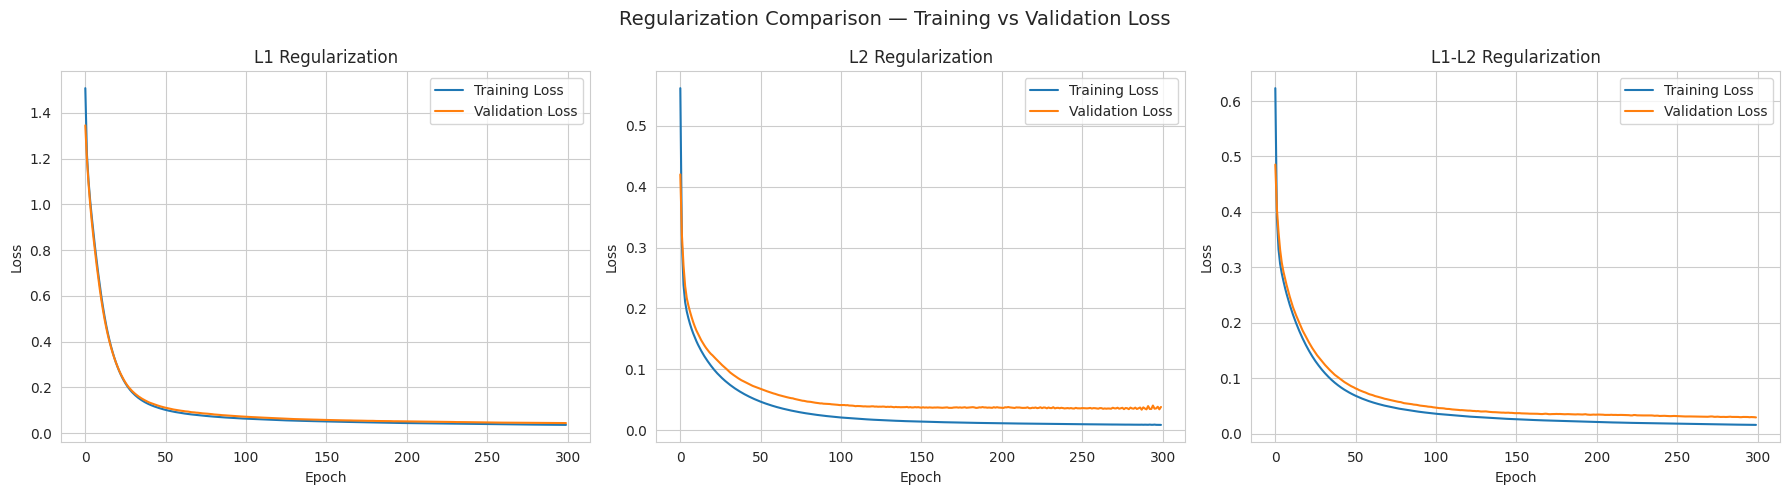

L2: minimum val_loss=0.034025, train/val loss gap at best val_loss=0.024615
L1: minimum val_loss=0.044298, train/val loss gap at best val_loss=0.007941
L1-L2: minimum val_loss=0.029687, train/val loss gap at best val_loss=0.013506


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, label in zip(axes, ["L1", "L2", "L1-L2"]):
    history = regularized_histories[label]

    ax.plot(history.history["loss"], label="Training Loss")
    ax.plot(history.history["val_loss"], label="Validation Loss")
    ax.set_title(f"{label} Regularization")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend()

fig.suptitle(
    "Regularization Comparison — Training vs Validation Loss",
    fontsize=14
)
plt.tight_layout()
plt.show()

for label, history in regularized_histories.items():
    train_loss = np.array(history.history["loss"])
    val_loss = np.array(history.history["val_loss"])

    print(
        f"{label}: minimum val_loss={val_loss.min():.6f}, "
        f"train/val loss gap at best val_loss={abs(train_loss[val_loss.argmin()] - val_loss.min()):.6f}"
    )


L2 Test Accuracy: 0.9386
              precision    recall  f1-score   support

   Malignant       0.87      0.98      0.92        42
      Benign       0.99      0.92      0.95        72

    accuracy                           0.94       114
   macro avg       0.93      0.95      0.94       114
weighted avg       0.94      0.94      0.94       114


L1 Test Accuracy: 0.9649
              precision    recall  f1-score   support

   Malignant       0.93      0.98      0.95        42
      Benign       0.99      0.96      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.97      0.96       114
weighted avg       0.97      0.96      0.97       114


L1-L2 Test Accuracy: 0.9561
              precision    recall  f1-score   support

   Malignant       0.91      0.98      0.94        42
      Benign       0.99      0.94      0.96        72

    accuracy                           0.96       114
   macro avg       0.95      0.96      0.95    

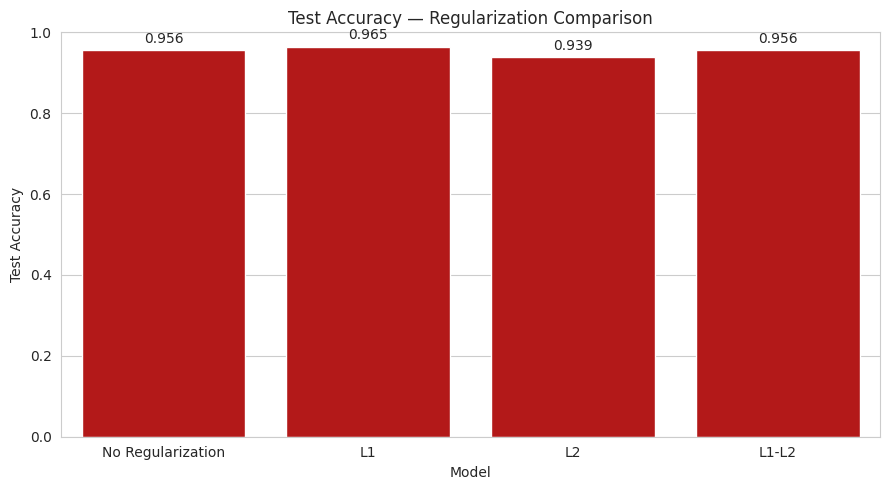

,Model,Test Accuracy
0,No Regularization,0.956140
1,L1,0.964912
2,L2,0.938596
3,L1-L2,0.956140


In [ ]:
regularized_accuracy = {}

for label, model in regularized_models.items():
    pred = (model.predict(X_test_sc, verbose=0).ravel() > 0.5).astype(int)
    acc = accuracy_score(y_test, pred)
    regularized_accuracy[label] = acc

    print(f"\n{label} Test Accuracy: {acc:.4f}")
    print(classification_report(
        y_test,
        pred,
        target_names=["Malignant", "Benign"],
        zero_division=0
    ))

no_reg_acc = accuracy_score(
    y_test,
    (model_mlp.predict(X_test_sc, verbose=0).ravel() > 0.5).astype(int)
)

accuracy_comparison = pd.DataFrame({
    "Model": ["No Regularization", "L1", "L2", "L1-L2"],
    "Test Accuracy": [
        no_reg_acc,
        regularized_accuracy["L1"],
        regularized_accuracy["L2"],
        regularized_accuracy["L1-L2"]
    ]
})

plt.figure(figsize=(9, 5))
ax = sns.barplot(
    data=accuracy_comparison,
    x="Model",
    y="Test Accuracy",
    color="#CC0000"
)
ax.set_title("Test Accuracy — Regularization Comparison")
ax.set_xlabel("Model")
ax.set_ylabel("Test Accuracy")
ax.set_ylim(0, 1)

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3)

plt.tight_layout()
plt.show()

display(accuracy_comparison)

In [ ]:
l2_reg = regularizers.l2(0.001)

model_final = keras.Sequential([
    keras.layers.Input(shape=(30,)),
    keras.layers.Dense(
        128,
        activation="relu",
        kernel_regularizer=l2_reg
    ),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(
        64,
        activation="relu",
        kernel_regularizer=l2_reg
    ),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(1, activation="sigmoid")
], name="Final_Combined_Model")

model_final.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model_final.summary()

es_final = EarlyStopping(
    monitor="val_loss",
    patience=20,
    restore_best_weights=True,
    verbose=1
)

history_final = model_final.fit(
    X_train_sc,
    y_train,
    epochs=300,
    batch_size=32,
    validation_split=0.1,
    callbacks=[es_final],
    verbose=1
)

Model: "Final_Combined_Model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_37 (Dense)                │ (None, 128)            │         3,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_38 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_39 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,289 (48.00 KB)

 Trainable params: 12,289 (48.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.8386 - loss: 0.5870 - val_accuracy: 0.9348 - val_loss: 0.4127
Epoch 2/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9413 - loss: 0.3371 - val_accuracy: 0.9348 - val_loss: 0.3153
Epoch 3/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9658 - loss: 0.2633 - val_accuracy: 0.9565 - val_loss: 0.2769
Epoch 4/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9682 - loss: 0.2427 - val_accuracy: 0.9565 - val_loss: 0.2488
Epoch 5/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9707 - loss: 0.2185 - val_accuracy: 0.9565 - val_loss: 0.2260
Epoch 6/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9780 - loss: 0.2065 - val_accuracy: 0.9783 - val_loss: 0.2121
Epoch 7/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9780 - loss: 0.1995 - val_accuracy: 0.9783 - val_loss: 0.2021
Epoch 8/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9804 - loss: 0.1905 - val_accuracy: 0.9783 - 

In [ ]:
def get_metrics(model):
    probabilities = model.predict(X_test_sc, verbose=0).ravel()
    predictions = (probabilities > 0.5).astype(int)

    return {
        "Test Accuracy": accuracy_score(y_test, predictions),
        "Test Precision": precision_score(y_test, predictions, zero_division=0),
        "Test Recall": recall_score(y_test, predictions, zero_division=0),
        "Test F1-Score": f1_score(y_test, predictions, zero_division=0)
    }

final_metrics = get_metrics(model_final)

results = []

def add_result(
    model_name,
    architecture,
    regularization,
    dropout_rate,
    early_stopping,
    model
):
    metrics = get_metrics(model)
    results.append({
        "Model": model_name,
        "Architecture": architecture,
        "Regularization": regularization,
        "Dropout Rate": dropout_rate,
        "Early Stopping": early_stopping,
        **metrics
    })

add_result(
    "SLP",
    "30→1",
    "None",
    0.0,
    "No",
    model_slp
)

add_result(
    "MLP-ReLU",
    "30→64→32→1",
    "None",
    0.0,
    "No",
    model_mlp
)

add_result(
    "MLP + Early Stopping",
    "30→128→64→1",
    "None",
    0.0,
    "Yes",
    model_es
)

add_result(
    "MLP + Dropout-best",
    f"30→128→64→1",
    "None",
    best_dropout_rate,
    "Yes",
    best_dropout_model
)

add_result(
    "MLP + L2",
    "30→128→64→1",
    "L2(0.001)",
    0.0,
    "Yes",
    regularized_models["L2"]
)

add_result(
    "Final Combined Model",
    "30→128→64→1",
    "L2(0.001)",
    0.3,
    "Yes",
    model_final
)

results_df = pd.DataFrame(results)

display(
    results_df.style.highlight_max(
        subset=["Test Accuracy", "Test F1-Score"],
        color="#ffcccc"
    )
)

,Model,Architecture,Regularization,Dropout Rate,Early Stopping,Test Accuracy,Test Precision,Test Recall,Test F1-Score
0,SLP,30→1,None,0.000000,No,0.947368,0.945946,0.972222,0.958904
1,MLP-ReLU,30→64→32→1,None,0.000000,No,0.956140,0.985507,0.944444,0.964539
2,MLP + Early Stopping,30→128→64→1,None,0.000000,Yes,0.964912,0.985714,0.958333,0.971831
3,MLP + Dropout-best,30→128→64→1,None,0.100000,Yes,0.947368,0.985294,0.930556,0.957143
4,MLP + L2,30→128→64→1,L2(0.001),0.000000,Yes,0.938596,0.985075,0.916667,0.949640
5,Final Combined Model,30→128→64→1,L2(0.001),0.300000,Yes,0.956140,0.985507,0.944444,0.964539


In [ ]:
add_result(
    "MLP + L1",
    "30→128→64→1",
    "L1(0.001)",
    0.0,
    "Yes",
    regularized_models["L1"]
)

add_result(
    "MLP + L1-L2",
    "30→128→64→1",
    "L1-L2(0.0001, 0.001)",
    0.0,
    "Yes",
    regularized_models["L1-L2"]
)

results_df = pd.DataFrame(results)

display(
    results_df.style.highlight_max(
        subset=["Test Accuracy", "Test F1-Score"],
        color="#ffcccc"
    )
)

,Model,Architecture,Regularization,Dropout Rate,Early Stopping,Test Accuracy,Test Precision,Test Recall,Test F1-Score
0,SLP,30→1,None,0.000000,No,0.947368,0.945946,0.972222,0.958904
1,MLP-ReLU,30→64→32→1,None,0.000000,No,0.956140,0.985507,0.944444,0.964539
2,MLP + Early Stopping,30→128→64→1,None,0.000000,Yes,0.964912,0.985714,0.958333,0.971831
3,MLP + Dropout-best,30→128→64→1,None,0.100000,Yes,0.947368,0.985294,0.930556,0.957143
4,MLP + L2,30→128→64→1,L2(0.001),0.000000,Yes,0.938596,0.985075,0.916667,0.949640
5,Final Combined Model,30→128→64→1,L2(0.001),0.300000,Yes,0.956140,0.985507,0.944444,0.964539
6,MLP + L1,30→128→64→1,L1(0.001),0.000000,Yes,0.964912,0.985714,0.958333,0.971831
7,MLP + L1-L2,30→128→64→1,"L1-L2(0.0001, 0.001)",0.000000,Yes,0.956140,0.985507,0.944444,0.964539


### Task 7.3 — Clinical Insight for Medical Diagnosis Support

For a clinical decision-support setting, model selection should not rely on accuracy alone. A false negative means a malignant case is predicted as benign, which is generally more costly than a false positive. Therefore, recall/sensitivity for the malignant class should receive high priority.

The default threshold is 0.5 in this notebook. For deployment, a lower threshold may be considered if it materially improves malignant-case recall while keeping false positives at an acceptable level. The threshold should ultimately be selected using clinical validation, not only this training dataset.

The most useful generalisation technique is the one that produces the strongest and most stable validation/test behaviour with a favourable recall and F1-score. Use the final results table to identify whether Early Stopping, Dropout, L2, or their combination provides the strongest evidence on this dataset.

This notebook does not treat the neural network as a standalone medical diagnostic device; it is a machine-learning project demonstrating decision-support modelling.

Final Combined Model — Classification Report
              precision    recall  f1-score   support

   Malignant       0.91      0.98      0.94        42
      Benign       0.99      0.94      0.96        72

    accuracy                           0.96       114
   macro avg       0.95      0.96      0.95       114
weighted avg       0.96      0.96      0.96       114



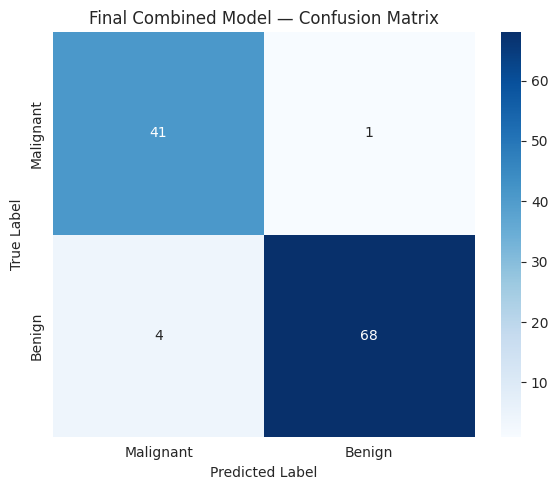

In [ ]:
final_pred = (
    model_final.predict(X_test_sc, verbose=0).ravel() > 0.5
).astype(int)

print("Final Combined Model — Classification Report")
print(classification_report(
    y_test,
    final_pred,
    target_names=["Malignant", "Benign"],
    zero_division=0
))

cm_final = confusion_matrix(y_test, final_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_final,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Malignant", "Benign"],
    yticklabels=["Malignant", "Benign"]
)
plt.title("Final Combined Model — Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

In [ ]:
os.makedirs("saved_model", exist_ok=True)
model_final.save("saved_model/breast_cancer_final_model.keras")

print("Saved: saved_model/breast_cancer_final_model.keras")

Saved: saved_model/breast_cancer_final_model.keras
